# 03 · Trading simulation, profitability vs benchmarks, deep analysis

Costs: 15 bps per side (30 bps round trip). Capital $10,000. TEST window 2024-01-01 → today.


In [1]:
import sys, warnings, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3})
from driftrev import config, store, artifacts, dataset, features, models, simulate, analysis, pipeline
print("data dir:", config.DATA_DIR)

data dir: /Users/mac/Documents/New project/stock-data-analysis/project/data


In [2]:
metrics = artifacts.load_metrics()
trades, eq = artifacts.load_frame("trades"), artifacts.load_frame("equity")

### Vector simulations (`sim1_` hold-to-horizon, `sim2_` with stop-loss / take-profit)

In [3]:
artifacts.load_frame("vector_sims.parquet").head(20).round(4)

,prediction,sim,n_trades,avg_trades_per_day,q75_trades_per_day,gross,fees,net,capital,cagr,hit_rate,avg_net_return
0,pred3_lgbm_best_rule_55,sim1,160,1.4286,1.0,524.6416,57.72,466.9216,1000.0,0.1452,0.6000,0.0292
1,pred3_lgbm_best_rule_55,sim2_sl_tp,160,1.4286,1.0,463.6852,57.72,405.9652,1000.0,0.1282,0.6000,0.0254
2,pred5_rf_best_rule_51,sim1,132,1.4348,1.0,429.5138,51.18,378.3338,1000.0,0.1203,0.5833,0.0287
3,pred5_rf_best_rule_51,sim2_sl_tp,132,1.4348,1.0,370.3351,51.18,319.1551,1000.0,0.1030,0.5833,0.0242
4,pred_manual_dgs10_dgs5,sim1,19496,60.9250,88.0,25951.5843,6440.24,19511.3443,88000.0,0.0734,0.5523,0.0100
5,pred4_logreg_best_rule_69,sim1,26,1.2381,1.0,211.7089,7.10,204.6089,1000.0,0.0681,0.7308,0.0787
6,pred4_logreg_best_rule_69,sim2_sl_tp,26,1.2381,1.0,210.6312,7.10,203.5312,1000.0,0.0678,0.7308,0.0783
7,pred8_ensemble_best_rule_52,sim1,190,1.4844,2.0,460.4014,71.20,389.2014,2000.0,0.0650,0.5474,0.0205
8,pred8_ensemble_best_rule_52,sim2_sl_tp,190,1.4844,2.0,432.6348,71.20,361.4348,2000.0,0.0606,0.5474,0.0190
9,pred_manual_dgs10_dgs5,sim2_sl_tp,19496,60.9250,88.0,22335.4767,6440.24,15895.2367,88000.0,0.0605,0.5523,0.0082


### Exact simulations (daily loop, reinvestment, max concurrent positions) vs benchmarks

In [4]:
res = pd.DataFrame(metrics["strategies"] + metrics["benchmarks"])
res[["name", "cagr", "sharpe", "sortino", "max_drawdown", "calmar", "rolling_1y_median", "n_trades", "win_rate", "final_equity"]].sort_values("cagr", ascending=False).round(3)

,name,cagr,sharpe,sortino,max_drawdown,calmar,rolling_1y_median,n_trades,win_rate,final_equity
13,SPY_buy_hold,0.191,1.194,1.761,-0.188,1.016,0.174,NaN,NaN,16482.196
15,hw1_momentum_top_quintile,0.170,0.859,1.225,-0.237,0.717,0.140,NaN,NaN,15635.470
5,model_crash_only,0.164,0.705,1.206,-0.192,0.854,0.172,66.0,0.515,15442.556
14,IWM_buy_hold,0.134,0.706,1.035,-0.275,0.487,0.148,NaN,NaN,14329.602
1,model_top5,0.084,0.431,0.684,-0.180,0.463,0.119,102.0,0.510,12583.000
7,model_long_short,0.049,0.413,0.659,-0.155,0.315,0.076,296.0,0.466,11464.045
6,model_breakout_only,0.043,0.475,0.759,-0.127,0.337,0.043,26.0,0.615,11272.026
4,model_pead_only,0.036,0.305,0.508,-0.159,0.225,0.024,56.0,0.518,11059.443
3,model_top5_risk_managed,0.014,0.167,0.250,-0.209,0.065,0.021,107.0,0.477,10396.750
11,guide_model_breakout_R,0.008,0.513,0.860,-0.021,0.390,0.020,24.0,0.500,10237.032


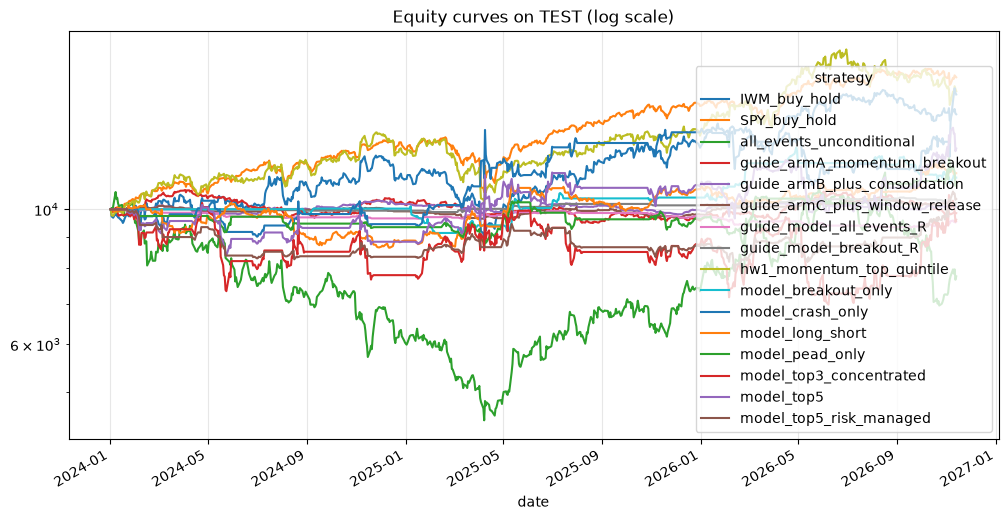

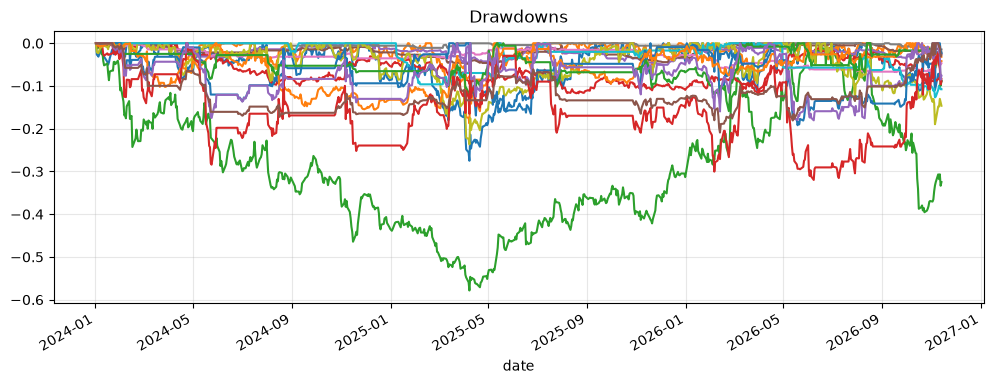

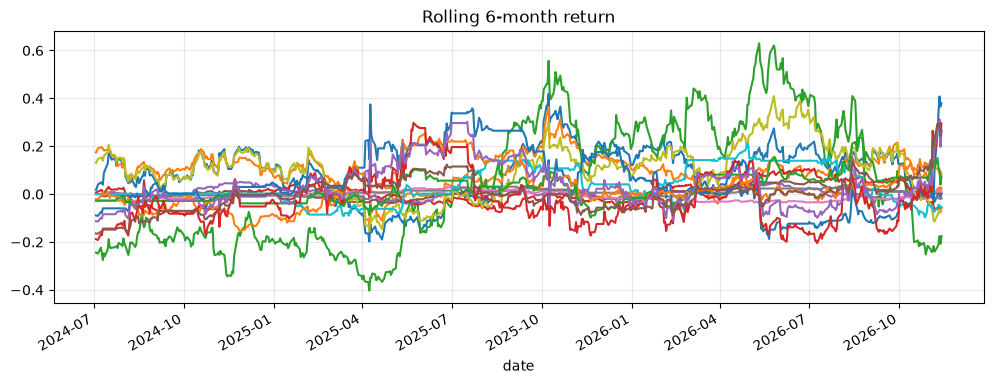

In [5]:
w = eq.pivot_table(index="date", columns="strategy", values="equity").ffill()
w.plot(logy=True, figsize=(12, 6), title="Equity curves on TEST (log scale)"); plt.show()
(w / w.cummax() - 1).plot(figsize=(12, 4), title="Drawdowns", legend=False); plt.show()
w.pct_change(126).plot(figsize=(12, 4), title="Rolling 6-month return", legend=False); plt.show()

### Trade anatomy of the best strategy

In [6]:
best = metrics.get("best_strategy"); print("best strategy:", best)
t = trades[trades.strategy == best]
display(t.groupby("exit_reason").agg(n=("pnl", "size"), avg_ret=("ret_net", "mean"), pnl=("pnl", "sum")).round(4))
display(t.groupby("event_family").agg(n=("pnl", "size"), win=("pnl", lambda s: (s > 0).mean()), avg_ret=("ret_net", "mean")).round(4))
t.sort_values("pnl").head(10)

best strategy: model_top5


,n,avg_ret,pnl
exit_reason,,,
time,102,0.0122,2018.49


,n,win,avg_ret
event_family,,,
earnings_crash,20,0.4000,-0.0341
earnings_down,18,0.6667,0.0464
earnings_up,27,0.3704,-0.0282
shock_crash,37,0.5946,0.0499


,strategy,ticker,side,event_family,event_date,prob,entry_date,entry_price,exit_date,exit_price,ret_net,pnl,exit_reason,days_held,notional,r_multiple
366,model_top5,CRNC,long,earnings_crash,2024-05-09,0.545731,2024-05-10,6.270000,2024-05-23,3.510000,-0.444091,-873.620406,time,10,1967.210740,NaN
438,model_top5,EMBC,long,earnings_crash,2026-05-05,0.547452,2026-05-06,3.990000,2026-05-19,2.900000,-0.277500,-652.599596,time,10,2351.710443,NaN
436,model_top5,CABO,long,shock_crash,2026-05-04,0.534586,2026-05-05,63.880001,2026-05-18,48.779999,-0.240790,-565.532503,time,10,2348.656452,NaN
455,model_top5,FUN,long,shock_crash,2026-10-13,0.521464,2026-10-14,9.960000,2026-10-27,7.710000,-0.230339,-542.872242,time,10,2356.841806,NaN
400,model_top5,FTRE,long,earnings_crash,2025-05-12,0.584092,2025-05-13,5.260000,2025-05-27,4.150000,-0.215499,-483.590173,time,10,2244.047656,NaN
421,model_top5,HUBS,long,shock_crash,2026-01-29,0.547105,2026-01-30,285.000000,2026-02-12,228.949997,-0.199372,-422.705251,time,10,2120.187065,NaN
420,model_top5,TTD,long,earnings_down,2026-01-26,0.539229,2026-01-27,33.520000,2026-02-09,27.040001,-0.194763,-421.754631,time,10,2165.478901,NaN
401,model_top5,TTGT,long,earnings_up,2025-06-04,0.529502,2025-06-05,8.380000,2025-06-18,6.800000,-0.193073,-412.180086,time,10,2134.843059,NaN
386,model_top5,MLKN,long,earnings_up,2025-03-27,0.533022,2025-03-28,20.110001,2025-04-10,16.549999,-0.181584,-366.718484,time,10,2019.554495,NaN
461,model_top5,FMC,long,earnings_up,2026-10-30,0.521551,2026-11-02,6.110000,2026-11-13,5.210000,-0.151931,-365.279421,time,10,2404.241173,NaN


### Where does the model work? Precision by event type, cause, sector, size, year, regime

In [7]:
bd = artifacts.load_frame("breakdown")
for dim in ["event_family", "edgar_category", "cap_bucket", "year", "regime_state", "sector", "prob_bucket"]:
    display(bd[bd.dimension == dim].sort_values("n", ascending=False).round(3))

,dimension,value,n,base_rate,n_selected,precision,avg_growth,avg_growth_all,lift
3,event_family,momentum_breakout,24264,0.386,29,0.483,1.020,1.005,0.096
2,event_family,earnings_up,8358,0.399,45,0.378,1.006,1.005,-0.021
1,event_family,earnings_down,7064,0.392,32,0.656,1.074,1.006,0.264
0,event_family,earnings_crash,1403,0.425,28,0.464,0.996,1.004,0.039
4,event_family,shock_crash,844,0.445,56,0.554,1.027,1.015,0.108


,dimension,value,n,base_rate,n_selected,precision,avg_growth,avg_growth_all,lift
10,edgar_category,none,22584,0.389,56,0.500,1.022,1.005,0.111
7,edgar_category,earnings,17132,0.398,107,0.486,1.021,1.005,0.088
11,edgar_category,offering,760,0.389,3,0.333,1.014,1.008,-0.056
12,edgar_category,regfd_other_8k,750,0.380,10,0.700,1.111,1.006,0.320
9,edgar_category,mgmt_change,387,0.403,7,0.714,1.039,1.005,0.311
6,edgar_category,deal,233,0.322,0,NaN,NaN,0.998,NaN
13,edgar_category,restatement_auditor,56,0.411,4,0.500,0.945,0.985,0.089
5,edgar_category,bankruptcy_delisting,21,0.429,2,0.500,1.040,1.012,0.071
8,edgar_category,impairment_restructuring,10,0.400,1,0.000,0.777,0.998,-0.400


,dimension,value,n,base_rate,n_selected,precision,avg_growth,avg_growth_all,lift
27,cap_bucket,small,15916,0.398,99,0.475,1.006,1.004,0.077
25,cap_bucket,large,14575,0.388,40,0.575,1.053,1.006,0.187
26,cap_bucket,mid,11442,0.390,51,0.510,1.037,1.005,0.120


,dimension,value,n,base_rate,n_selected,precision,avg_growth,avg_growth_all,lift
29,year,2025,14431,0.387,86,0.581,1.053,1.004,0.195
30,year,2026,13968,0.405,77,0.481,1.015,1.006,0.075
28,year,2024,13534,0.385,27,0.333,0.959,1.005,-0.052


,dimension,value,n,base_rate,n_selected,precision,avg_growth,avg_growth_all,lift
44,regime_state,normal,38876,0.383,141,0.426,1.004,1.003,0.042
43,regime_state,elevated,2216,0.489,35,0.714,1.083,1.026,0.225
45,regime_state,stressed,841,0.553,14,0.786,1.080,1.032,0.233


,dimension,value,n,base_rate,n_selected,precision,avg_growth,avg_growth_all,lift
21,sector,Information Technology,7522,0.441,45,0.556,1.023,1.011,0.115
20,sector,Industrials,6953,0.395,26,0.500,1.029,1.007,0.105
15,sector,Consumer Discretionary,5707,0.377,32,0.625,1.046,1.000,0.248
18,sector,Financials,5266,0.389,15,0.467,1.016,1.005,0.077
19,sector,Health Care,5196,0.388,36,0.444,1.026,1.005,0.056
17,sector,Energy,2686,0.403,2,1.000,1.183,1.004,0.597
22,sector,Materials,2083,0.394,10,0.400,0.987,1.002,0.006
16,sector,Consumer Staples,1875,0.363,8,0.625,1.047,1.004,0.262
23,sector,Real Estate,1813,0.326,4,0.000,0.974,1.000,-0.326
14,sector,Communication Services,1418,0.353,12,0.333,0.971,0.997,-0.019


,dimension,value,n,base_rate,n_selected,precision,avg_growth,avg_growth_all,lift
69,prob_bucket,"(0.0, 0.4]",29951,0.374,0,NaN,NaN,1.004,NaN
70,prob_bucket,"(0.4, 0.5]",11524,0.435,0,NaN,NaN,1.008,NaN
71,prob_bucket,"(0.5, 0.55]",418,0.505,150,0.507,1.028,1.028,0.002
72,prob_bucket,"(0.55, 0.6]",37,0.514,37,0.514,1.016,1.016,0.000
73,prob_bucket,"(0.6, 0.65]",3,0.333,3,0.333,0.925,0.925,0.000


### Debugging the most confident wrong predictions

In [8]:
artifacts.load_frame("false_positives.parquet")

,date,ticker,company,event_family,edgar_category,edgar_items,proba_ensemble,abn_ret_1d,growth_future_10d,mae_10d,regime_state,sector
0,2024-08-15,RILY,B. Riley Financial,shock_crash,none,,0.621806,-0.295229,0.876800,-0.228800,normal,Financials
1,2024-05-17,CRNC,Cerence,shock_crash,mgmt_change,5.02,0.600402,-0.186462,0.839109,-0.217822,normal,Information Technology
2,2025-05-12,FTRE,Fortrea,earnings_crash,earnings,"2.02,5.02,7.01,8.01",0.584092,-0.206313,0.788973,-0.241255,normal,Health Care
3,2024-08-13,RILY,B. Riley Financial,shock_crash,restatement_auditor,,0.580055,-0.136747,0.806452,-0.367461,normal,Financials
4,2024-11-06,SEDG,SolarEdge,shock_crash,earnings,"2.02,5.02",0.575147,-0.269781,0.847233,-0.201871,normal,Information Technology
5,2025-05-06,SRPT,Sarepta Therapeutics,shock_crash,earnings,,0.570191,-0.256326,1.000000,-0.147287,elevated,Health Care
6,2024-02-05,FLG,Flagstar Bank,shock_crash,none,,0.564401,-0.098291,0.857404,-0.341865,normal,Financials
7,2025-07-17,SRPT,Sarepta Therapeutics,earnings_up,earnings,"2.02,2.05,5.02",0.563334,0.188514,0.967020,-0.386337,normal,Health Care
8,2026-10-30,PMT,PennyMac Mortgage Investment Trust,earnings_up,earnings,"2.02,5.02,8.01",0.561909,0.021867,0.963777,-0.071151,normal,Real Estate
9,2024-08-12,RILY,B. Riley Financial,earnings_crash,restatement_auditor,2.02,0.560894,-0.519966,0.805405,-0.390541,normal,Financials
